# Using the broker Fink, get and plot the detection light curve and the forced photometry light curve, given an object id

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import time
import threading
from concurrent.futures import ThreadPoolExecutor
import glob

import io
import requests
from astropy.io import fits  # Optional: only if you want to inspect them right away


# Plot the detection light curve

In [2]:
oid = 170019696266444924

sources_url = "https://api.lsst.fink-portal.org/api/v1/sources"
payload = {
    "diaObjectId": str(oid),
    "columns": "r:diaSourceId,r:midpointMjdTai,r:psfFlux, r:psfFluxErr, r:band, r:reliability"
}

response = requests.post(sources_url, json=payload)


if response.status_code == 200:
    try:
      light_curve_df = pd.read_json(io.BytesIO(response.content))
      target_source_id = response.json()[-1]["r:diaSourceId"]
      print(f"Target diaSourceId found: {target_source_id}")
    except:
      print(f"No diaSourceId found for {oid}")
else:
    print(f"Error fetching sources: {response.status_code}")




Target diaSourceId found: 170019696266444924


In [3]:
light_curve_df

,r:band,r:diaSourceId,r:midpointMjdTai,r:psfFlux,r:psfFluxErr,r:reliability
0,i,170076861466935314,61101.030547,3164.2937,340.11087,0.775797
1,r,170072470564372487,61100.077972,3206.8325,317.03983,0.804835
2,i,170068070222004265,61099.043840,3490.8540,294.01392,0.900930
3,r,170063689203843080,61098.102265,2834.2788,307.88010,0.741619
4,r,170063688951660584,61098.101393,3208.9514,283.22504,0.942564
...,...,...,...,...,...,...
286,i,170028486583386157,61090.054840,3379.9380,242.17989,0.848605
287,i,170028486308659266,61090.053976,3095.7747,261.15740,0.622744
288,i,170028486042320970,61090.053112,3399.5918,242.86244,0.771463
289,i,170028485776506945,61090.048021,3152.4004,234.82335,0.890567


In [4]:
filter_colors = {
    "u": "#1600ea",
    "g": "#49be61",
    "r": "#c61c00",
    "i": "#ffc200",
    "z": "#f341a2",
    "y": "#5d0000",
}

In [5]:
for coloru in filter_colors:
  print(coloru)


u
g
r
i
z
y


In [11]:
import astropy.units as u

In [13]:
def add_prv_mag(flux, flux_err):
    """Convert flux (nJy) to AB magnitude (asymmetric error from flux ± fluxErr)"""
    flux = np.asarray(flux, dtype="float64")
    flux_err = np.asarray(flux_err, dtype="float64")
    mag = u.nJy.to(u.ABmag, flux)
    upper = u.nJy.to(u.ABmag, flux + flux_err)
    lower = u.nJy.to(u.ABmag, flux - flux_err)
    mag_err = -(upper - lower) / 2
    # return {"psfMag": mag, "psfMagErr": mag_err}
    return mag, mag_err

In [14]:
light_curve_df['r:psfMag'], light_curve_df['r:psfMagErr'] = add_prv_mag(light_curve_df['r:psfFlux'], light_curve_df['r:psfFluxErr'])

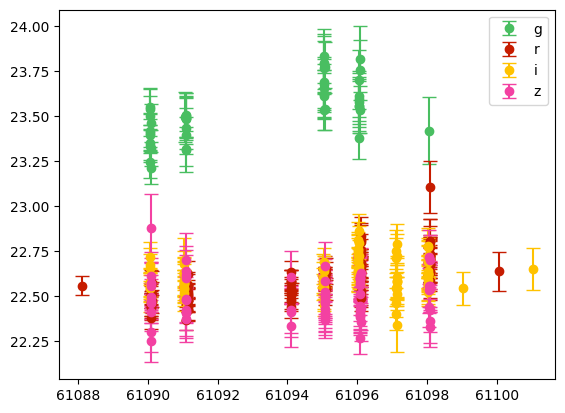

In [15]:

fig, ax  = plt.subplots()
for coloru in filter_colors:
  df = light_curve_df[light_curve_df["r:band"] == coloru]
  if len(df) > 0:
    scatt = ax.errorbar(df['r:midpointMjdTai'],df['r:psfMag'], yerr=df['r:psfMagErr'],
                    color=filter_colors[coloru],  fmt='o', capsize=5,
                    label=coloru)


plt.legend()


(array([  7.,   4.,  11.,  10.,  22.,  21.,  17.,  21.,  58., 120.]),
 array([0.13200398, 0.21782799, 0.303652  , 0.38947602, 0.47530003,
        0.56112404, 0.64694805, 0.73277206, 0.81859608, 0.90442009,
        0.9902441 ]),
 <BarContainer object of 10 artists>)

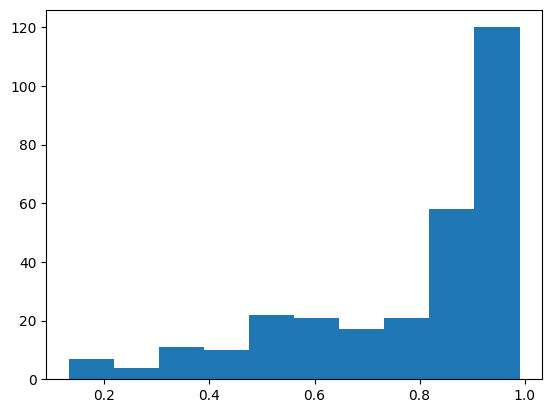

In [7]:
plt.hist(light_curve_df["r:reliability"])

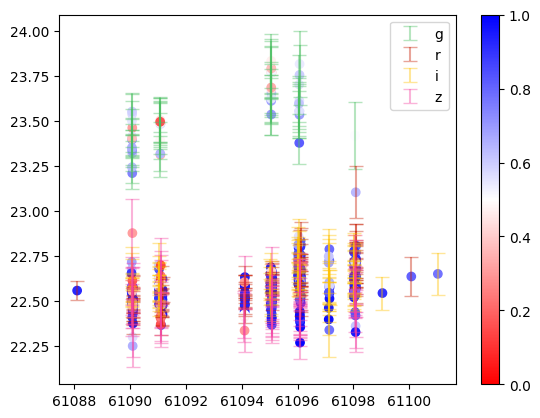

In [16]:
fig, ax  = plt.subplots()
for coloru in filter_colors:
  df = light_curve_df[light_curve_df["r:band"] == coloru]
  if len(df) > 0:
    scatt = ax.errorbar(df['r:midpointMjdTai'],df['r:psfMag'], yerr=df['r:psfMagErr'],
                    color=filter_colors[coloru],  fmt='none', capsize=5,
                    label=coloru, alpha=0.4)

    cc = plt.scatter(df['r:midpointMjdTai'],df['r:psfMag'], c=df["r:reliability"], cmap='bwr_r', clim=(0,1))
plt.colorbar(cc)

plt.legend()

# Plot the forced photometry light curve

In [9]:


oid = 170019696266444924

sources_url = "https://api.lsst.fink-portal.org/api/v1/fp"
payload = {
    "diaObjectId": str(oid),
    "columns": "r:midpointMjdTai,r:psfFlux, r:psfFluxErr, r:band"
}

response = requests.post(sources_url, json=payload)


if response.status_code == 200:
    try:
      fp_light_curve_df = pd.read_json(io.BytesIO(response.content))

      print(f"Target diaSourceId found")
    except:
      print(f"No diaSourceId found for {oid}")
else:
    print(f"Error fetching sources: {response.status_code}")

Target diaSourceId found


In [17]:
fp_light_curve_df['r:psfMag'], fp_light_curve_df['r:psfMagErr'] = add_prv_mag(fp_light_curve_df['r:psfFlux'], fp_light_curve_df['r:psfFluxErr'])


/usr/local/lib/python3.13/dist-packages/astropy/units/function/logarithmic.py:67: RuntimeWarning: invalid value encountered in log10
  return dex.to(self._function_unit, np.log10(x))


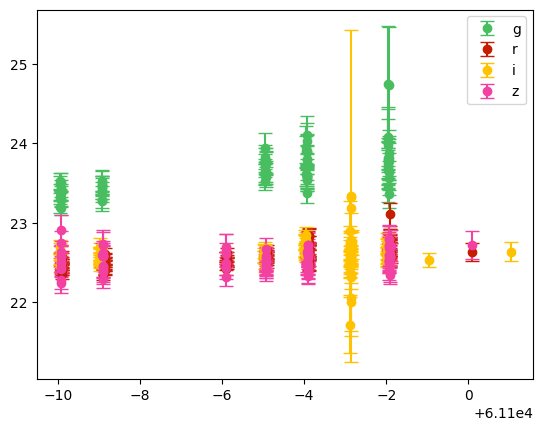

In [18]:
fig, ax  = plt.subplots()
for coloru in filter_colors:
  df = fp_light_curve_df[fp_light_curve_df["r:band"] == coloru]
  if len(df) > 0:
    scatt = ax.errorbar(df['r:midpointMjdTai'],df['r:psfMag'], yerr=df['r:psfMagErr'],
                    color=filter_colors[coloru],  fmt='o', capsize=5,
                    label=coloru)


plt.legend()